# Tutorial 3: packed-bed models

A packed-bed heat battery is a tank filled with capsules of phase-change material (PCM),
usually spheres, with the heat transfer fluid (HTF) flowing through the voids between
them. The large capsule surface makes heat transfer easy, and the capsules are simple to
make and replace.

The bed has length $Z$ along the flow, cross-sectional area $A$ and porosity
$\varepsilon$, the volume fraction of the voids. The capsules are spheres of radius $R$.
The model assumes that all capsules at the same height are the same, so one capsule stands
for all of those at each height. The positions are

- $z$, along the bed from the inlet,
- $r$, the distance from the centre of a capsule, from 0 to $R$.

The default parameter values are the experiments of Nallusamy et al. (2007): a 47 l tank
of paraffin capsules, initially at 32 °C, charged with water at 70 °C.

The [Packed bed](https://pytes.readthedocs.io/en/latest/models/packed_bed.html) page of the documentation describes the geometry, the equations and the options of this model in full, with sketches.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes

model = pytes.PackedBedModel()
parameter_values = model.default_parameter_values
for name in [
    "Bed length [m]",
    "Bed cross-sectional area [m2]",
    "Bed porosity",
    "Capsule radius [m]",
]:
    print(f"{name}: {parameter_values[name]:.4g}")

Bed length [m]: 0.46
Bed cross-sectional area [m2]: 0.1018
Bed porosity: 0.5
Capsule radius [m]: 0.0275


## The equations

The fluid flows through the voids, a flow area $\varepsilon A$, carrying its specific
enthalpy $h$:

$$
\varepsilon A \rho \frac{\partial h}{\partial t} + \dot m \frac{\partial h}{\partial z} = q',
$$

where $q'$ is the heat the fluid gains per unit length of bed. Inside each capsule, heat is
conducted radially by the enthalpy method, in spherical coordinates:

$$
\frac{\partial H}{\partial t} = \frac{1}{r^2} \frac{\partial}{\partial r}
\left( r^2 k \frac{\partial T}{\partial r} \right),
$$

with no flux at the centre and a flux $h_c (T_f - T_s)$ from the fluid into the capsule at
its surface. The bed holds $3 (1 - \varepsilon) / R$ of capsule surface per unit volume, so
the fluid gains $q' = 3 (1 - \varepsilon) A h_c (T_s - T_f) / R$ per unit length.

The model is built from the same submodels as the finned-tube models, with a different
geometry:

In [2]:
for name, submodel in model.submodels.items():
    print(f"{name}: {type(submodel).__name__}")

fluid: AdvectedFluid
storage: EnthalpyStorage
coupling: WallCoupling
device energy: DeviceEnergy
per-area totals: PerAreaTotals


## Against the measurements

The model is solved for the 160 minutes of the experiment, and the fluid temperature at a
quarter, half, three quarters and the full height of the bed (lines) is compared with the
measurements (points).

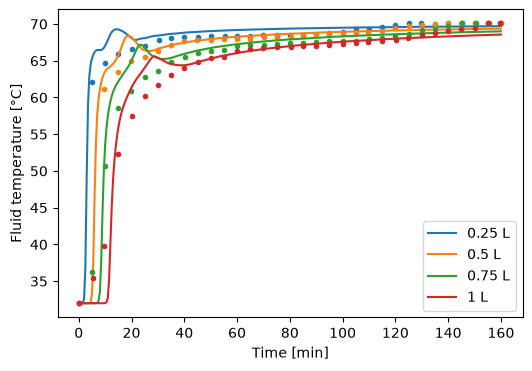

In [3]:
t_end = 160 * 60
t_eval = np.linspace(0, t_end, 321)
solution = pybamm.Simulation(model).solve([0, t_end], t_interp=t_eval)

Z = parameter_values["Bed length [m]"]
fig, ax = plt.subplots(figsize=(6, 4))
for position, fraction in [("0.25L", 0.25), ("0.5L", 0.5), ("0.75L", 0.75), ("1L", 1)]:
    t_data, T_data = np.loadtxt(
        f"../data/Nallusamy2007_HTF_{position}.csv",
        delimiter=",",
        skiprows=1,
        unpack=True,
    )
    T = solution["Heat transfer fluid temperature [degC]"](t=t_eval, z=fraction * Z)
    (line,) = ax.plot(t_eval / 60, T, label=f"{fraction:g} L")
    ax.plot(t_data, T_data, "o", color=line.get_color(), markersize=3)
ax.set_xlabel("Time [min]")
ax.set_ylabel("Fluid temperature [°C]")
ax.legend()
plt.show()

A thermal front moves up the bed: the fluid near the inlet warms first, and each height
pauses near the 60 °C melting temperature while the capsules there melt.

## Inside a capsule

Because each capsule is resolved, the model also gives the temperature inside the
capsules. Halfway up the bed, the capsule first warms as a solid, from its surface inwards.
Once it reaches the 60 °C melting temperature, it holds there while a liquid shell grows
slowly from the surface towards the centre: the poorly conducting paraffin limits how fast
the bed charges.

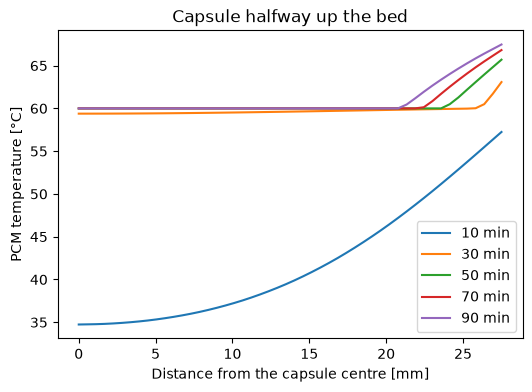

In [4]:
R = parameter_values["Capsule radius [m]"]
r = np.linspace(0, R, 50)
pcm_temperature = solution["Phase-change material temperature [degC]"]

fig, ax = plt.subplots(figsize=(6, 4))
for minutes in [10, 30, 50, 70, 90]:
    T = pcm_temperature(t=60 * minutes, r=r, z=Z / 2)
    ax.plot(1e3 * r, T, label=f"{minutes} min")
ax.set_xlabel("Distance from the capsule centre [mm]")
ax.set_ylabel("PCM temperature [°C]")
ax.set_title("Capsule halfway up the bed")
ax.legend()
plt.show()

## Resolved or averaged along the bed

As for the finned tubes ([Tutorial 2](tutorial_2_finned_tube_models.ipynb)), the option `"storage along flow path": "averaged"` replaces the
capsules along the bed with one capsule that stands for their average, exchanging heat with
the fluid averaged along the bed.

resolved   2.31 s


averaged   0.26 s


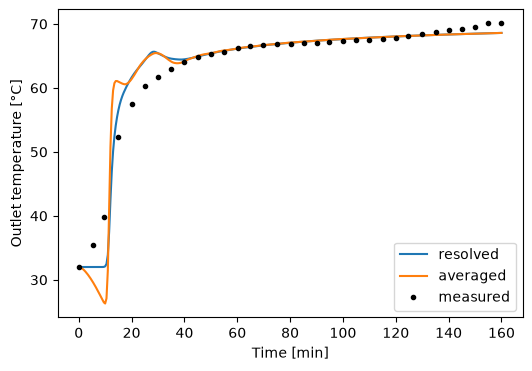

In [5]:
variants = {
    "resolved": model,
    "averaged": pytes.PackedBedModel(options={"storage along flow path": "averaged"}),
}
solutions = {}
for label, variant in variants.items():
    start = time.perf_counter()
    solutions[label] = pybamm.Simulation(variant).solve([0, t_end], t_interp=t_eval)
    print(f"{label:9s} {time.perf_counter() - start:5.2f} s")

t_data, T_data = np.loadtxt(
    "../data/Nallusamy2007_HTF_1L.csv", delimiter=",", skiprows=1, unpack=True
)
fig, ax = plt.subplots(figsize=(6, 4))
for label, sol in solutions.items():
    ax.plot(
        sol["Time [min]"].entries, sol["Outlet temperature [degC]"].entries, label=label
    )
ax.plot(t_data, T_data, "ko", markersize=3, label="measured")
ax.set_xlabel("Time [min]")
ax.set_ylabel("Outlet temperature [°C]")
ax.legend()
plt.show()

The averaged bed is much faster, and once the front has crossed the bed the two agree
closely. The fluid is still resolved along the bed, and the front crosses it in about ten
minutes, while the capsules take well over an hour to melt: the capsules along the bed are at
similar temperatures, and one capsule stands for them well.

Before the front arrives, the averaged outlet dips below the initial 32 °C. The averaged
capsule takes its heat from the fluid uniformly along the bed, including near the outlet,
where the fluid is still cold. This is a known artefact of the averaged formulation, and
energy is still conserved exactly. Where the arrival of the front matters, or the capsules
melt about as fast as the front moves, use the resolved model.

The packed bed has one more option, `"storage element": "lumped"`, which gives each
capsule a uniform temperature instead of resolving it: much cheaper, and accurate for small
or highly conductive capsules. See the [lumped capsule](../lumped_capsule.ipynb) example.

Next: [Tutorial 4: changing parameter values](tutorial_4_parameter_values.ipynb).